# 2.2 Running the model in GreenLight

## Live code in this page

This page uses **live code**. Click the rocket button (🚀) at the top of this page, above the title, then choose "▶ Live Code". The loading may take some time so it is good to start the Live Code before reading on. The Live Code engine is ready when you see a text under the page's title, stating something like "**Launching from mybinder.org: `ready`**.

**Note:** Code that you edit in the live code blocks is not saved. Any changes you make to the code blocks is lost once you move on from the page. Therefore, if you want to keep your work, save a copy of it in a local document.

The code block below defines some imports and functions that will be helpful in the current page. It is run automatically when you run the "▶ Live Code" button. You may have a look at it if you like, but that is not necessary for this course.

In [19]:
import pandas as pd

def display_dict(d, dict_type="nested"):
    """
    Below, some dictionaries will be define in the standard
    GreenLight format for describing models.
    This functions displays such dictionaries in a nicely
    readable format
    """
    if dict_type == "nested":
        df = pd.DataFrame.from_dict(d, orient="index")
        df.index.name = "Variable"
    elif dict_type == "flat":
        df = pd.DataFrame.from_dict(d, orient="index", columns=[""])
    display(df)

## What we have so far

At the end of the previous section, we've finished defining the simple crop model in a Python dict. Run the code block below to load this dict into the variable `crop_definition`.

In [15]:
"""
Solution to Exercise 6: complete the crop definition dict with description, unit, type, definition, and reference
"""

crop_definition = {
    "W": {
        "description": "Crop dry mass",
        "unit": "g/m2",
        "type": "state",
        "definition": "LUE * ( 1 - exp(-k*LAI) ) * (1/1000000 * Iw)",  # The expression for dW/dT (for states, the definition is the right hand sand of the ODE)
        "init": "75",
        "reference": "Stanghellini (2019), Eq. 2.25. I (MJ/m2/day) is replaced by Iw (W/m2). See also Figure 2.13 there: 75 g/m2 dry mass is a reasonable value for a small crop"
    },
    "LUE": {
        "description": "Light use efficiency",
        "unit": "g crop weight per MJ PAR",
        "type": "const",
        "definition": "4.3",
        "reference": "Stanghellini (2019), Eq. 2.25. See also pg. 49 there: 4.3 is a typical middle value"
    },
    "k": {
        "description": "Light extinction coefficient",
        "unit": "-",
        "type": "const",
        "definition": "0.7",
        "reference": "Stanghellini (2019), Eq. 2.25. See also pg. 39 there: 'For many greenhouse crops, k has a value between 0.6 and 0.8'"
    },
    "LAI": {
        "description": "Leaf area index",
        "unit": "m2 leaf per m2 floor",
        "type": "aux",
        "definition": "W * F_leaves * SLA / 10000",
        "reference": "Stanghellini (2019), Eq. 2.26. "
    },
    "Iw": {
        "description": "Solar PAR radiation",
        "unit": "W PAR per m2",
        "type": "input",
        "definition": "50",
        "reference": "Stanghellini (2019), Eq. 2.25. I (MJ/m2/day) has been replaced by Iw (W/m2). The value of 50 W/m2 is given as an example"
    },
    "F_leaves": {
        "description": "Fraction of crop dry mass partitioned to the leaves",
        "unit": "-",
        "type": "const",
        "definition": "0.8",
        "reference": "Stanghellini (2019), Eq. 2.26. 0.8 is chosen to represent a vegetative crop with mostly leaves"
    },
    "SLA": {
        "description": "Specific leaf area",
        "unit": "cm2/g",
        "type": "const",
        "definition": "250",
        "reference": "Stanghellini (2019), Eq. 2.26. 250 is a middle value for a tomato crop (see Table 2.1, pg. 50 in Stanghellini 2019)"
    }   
 }

# Display the above dict
display_dict(crop_definition)

,description,unit,type,definition,init,reference
Variable,,,,,,
W,Crop dry mass,g/m2,state,LUE * ( 1 - exp(-k*LAI) ) * (1/1000000 * Iw),75,"Stanghellini (2019), Eq. 2.25. I (MJ/m2/day) i..."
LUE,Light use efficiency,g crop weight per MJ PAR,const,4.3,NaN,"Stanghellini (2019), Eq. 2.25. See also pg. 49..."
k,Light extinction coefficient,-,const,0.7,NaN,"Stanghellini (2019), Eq. 2.25. See also pg. 39..."
LAI,Leaf area index,m2 leaf per m2 floor,aux,W * F_leaves * SLA / 10000,NaN,"Stanghellini (2019), Eq. 2.26."
Iw,Solar PAR radiation,W PAR per m2,input,50,NaN,"Stanghellini (2019), Eq. 2.25. I (MJ/m2/day) h..."
F_leaves,Fraction of crop dry mass partitioned to the l...,-,const,0.8,NaN,"Stanghellini (2019), Eq. 2.26. 0.8 is chosen t..."
SLA,Specific leaf area,cm2/g,const,250,NaN,"Stanghellini (2019), Eq. 2.26. 250 is a middle..."


## Running the model in GreenLight

The code block below loads the crop model definition `dict` that we've created, `crop_definition`, onto a new GreenLight object. This is done by using a Python class constructor - a method that creates a new instance of a class, in this case, an instance of the class `GreenLight`.

In this code, we give `crop_definition` as the `input_prompt` argument for the `GreenLight` constructor. This sets our model definition in the new `GreenLight` instance, called `crop_mdl`.

Then, the method `run()` is called for `crop_mdl`, and the model runs.

In [4]:
"""
Load the crop model definition to a GreenLight object, and then run it
"""

# Import the GreenLight package
import greenlight

# Create a new GreenLight object. Provide the dict crop_definition as input prompt
crop_mdl = greenlight.GreenLight(input_prompt=crop_definition)

# Run the model
crop_mdl.run()

C:\Users\katzi001\.conda\envs\intro_gh_modelling\Lib\site-packages\greenlight\_solve\_solve_ivp.py:23: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.integrate import solve_ivp




Simulation started at time (ISO format): 2026-11-09T20:21:06.439401
Running: 100.00%

Simulation complete at time (ISO format): 2026-11-09T20:21:06.503159
Simulated 1.0 days
Elapsed time: 0.06375741958618164 seconds
Output saved to file \\wurnet.nl\dfs-root\PROJECTS\Horticulture_Projects\3742395500_OpenUpEduGh_DK\04_Data_OpenUpEduGh\intro_gh_modelling\notebooks\L2_implementing_the_crop_model\output\greenlight_output_20261109_2021.csv
Model structure log saved to \\wurnet.nl\dfs-root\PROJECTS\Horticulture_Projects\3742395500_OpenUpEduGh_DK\04_Data_OpenUpEduGh\intro_gh_modelling\notebooks\L2_implementing_the_crop_model\output\greenlight_output_20261109_2021_model_struct_log.json
Simulation log saved to \\wurnet.nl\dfs-root\PROJECTS\Horticulture_Projects\3742395500_OpenUpEduGh_DK\04_Data_OpenUpEduGh\intro_gh_modelling\notebooks\L2_implementing_the_crop_model\output\greenlight_output_20261109_2021_simulation_log.txt


If all went well, the model run printed out some text, which mentioned that some files were saved once the run was complete. At this moment we don't need to use these files, since the model result is also stored in the object `crop_mdl`.

The code blocks below show some of the information that is stored in `crop_mdl`.

In [20]:
"""
Display some of the information that is stored in crop_mdl
"""

print("\ncrop_mdl.variables:")
display_dict(crop_mdl.variables, "flat")

print("\ncrop_mdl.var_descriptions:")
display_dict(crop_mdl.var_descriptions, "flat")

print("\ncrop_mdl.var_units:")
display_dict(crop_mdl.var_units, "flat")

print("\ncrop_mdl.var_refs:")
display_dict(crop_mdl.var_refs, "flat")


crop_mdl.variables:


,
W,LUE * ( 1 - exp(-k*LAI) ) * (1/1000000 * Iw)
LUE,4.3
k,0.7
LAI,W * F_leaves * SLA / 10000
Iw,50
F_leaves,0.8
SLA,250



crop_mdl.var_descriptions:


,
W,Crop dry mass
LUE,Light use efficiency
k,Light extinction coefficient
LAI,Leaf area index
Iw,Solar PAR radiation
F_leaves,Fraction of crop dry mass partitioned to the l...
SLA,Specific leaf area



crop_mdl.var_units:


,
W,g/m2
LUE,g crop weight per MJ PAR
k,-
LAI,m2 leaf per m2 floor
Iw,W PAR per m2
F_leaves,-
SLA,cm2/g



crop_mdl.var_refs:


,
W,"Stanghellini (2019), Eq. 2.25. I (MJ/m2/day) i..."
LUE,"Stanghellini (2019), Eq. 2.25. See also pg. 49..."
k,"Stanghellini (2019), Eq. 2.25. See also pg. 39..."
LAI,"Stanghellini (2019), Eq. 2.26."
Iw,"Stanghellini (2019), Eq. 2.25. I (MJ/m2/day) h..."
F_leaves,"Stanghellini (2019), Eq. 2.26. 0.8 is chosen t..."
SLA,"Stanghellini (2019), Eq. 2.26. 250 is a middle..."


In [21]:
"""
Display the model result in a table
"""

print("\ncrop_mdl.full_sol")
display(crop_mdl.full_sol)


crop_mdl.full_sol


,Time,W,Iw,LAI
0,0.0,75.000000,50.0,1.500000
1,3600.0,75.504562,50.0,1.510091
2,7200.0,76.011107,50.0,1.520222
3,10800.0,76.519151,50.0,1.530383
4,14400.0,77.028973,50.0,1.540579
5,18000.0,77.540646,50.0,1.550813
6,21600.0,78.054191,50.0,1.561084
7,25200.0,78.569606,50.0,1.571392
8,28800.0,79.086885,50.0,1.581738
9,32400.0,79.606019,50.0,1.592120


## Displaying the model results in a graph

Now that we have seen that some model results have been generated, it is convenient to be able to show some graphs. The following code block creates a graph for each variable that is not a constant.

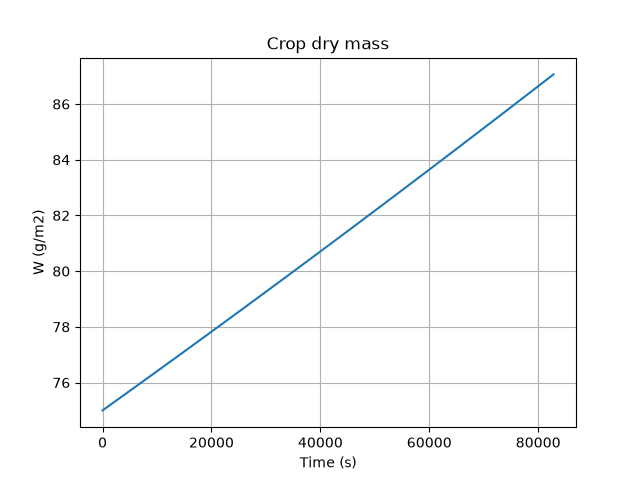

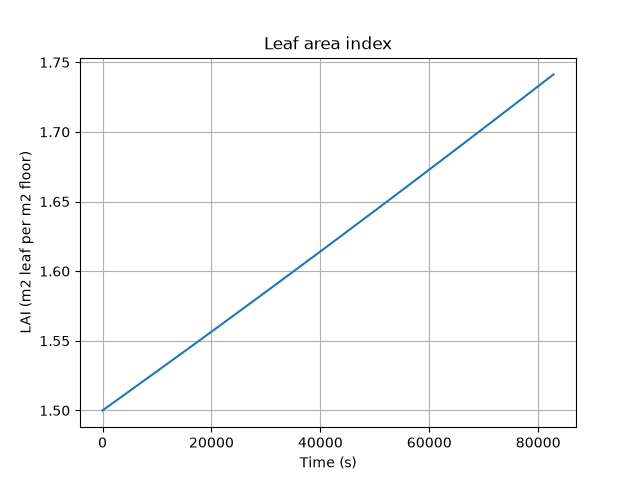

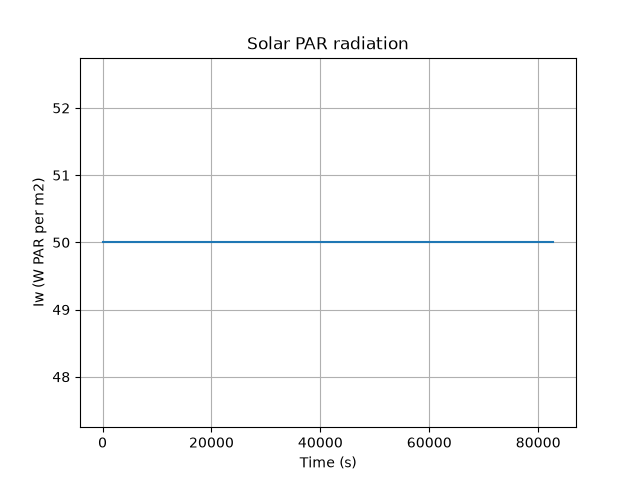

In [22]:
"""
Generate a graph for each variable of the model that is not a constant
"""
%matplotlib widget
import matplotlib.pyplot as plt

for var in crop_mdl.variables.keys():
    if var not in crop_mdl.consts.keys():
        plt.figure()
        plt.plot(
            crop_mdl.full_sol["Time"],
            crop_mdl.full_sol[var]
        )
        plt.title(crop_mdl.var_descriptions[var])
        plt.ylabel(var + " (" + crop_mdl.var_units[var] + ")")
        plt.xlabel("Time (s)")
        plt.grid()
        plt.show()

In [ ]:
import traceback
import ipywidgets as widgets
import pandas as pd

from IPython.display import display, clear_output

slider_names = [
    "W init",
    "Iw",
    "LUE"
]


output = widgets.Output()

# --------------------------------------------------
# 1. Define the input sliders
# --------------------------------------------------

slider_1 = widgets.FloatSlider(
    value=75,
    min=0,
    max=250,
    step=0.1,
    description=slider_names[0],
    continuous_update=False
)

slider_2 = widgets.FloatSlider(
    value=200,
    min=0,
    max=1000,
    step=1,
    description=slider_names[1],
    continuous_update=False
)

slider_3 = widgets.IntSlider(
    value=4.3,
    min=0,
    max=20,
    step=0.01,
    description=slider_names[2],
    continuous_update=False
)


# --------------------------------------------------
# 2. Define the buttons
# --------------------------------------------------

run_button = widgets.Button(
    description='Run model',
    button_style='success',
    icon='play'
)

delete_button = widgets.Button(
    description='Delete latest curve',
    button_style='danger',
    icon='trash'
)


# --------------------------------------------------
# 3. Set up the plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

ax.set_xlabel('Time')
ax.set_ylabel('Model output')
ax.set_title('Model trajectories')
ax.grid(True, alpha=0.3)

# Store the curves and their labels
curves = []


# --------------------------------------------------
# 4. Function to run the model
# --------------------------------------------------
import copy

def run_model(button):

    try:
        # Read slider values
        p1 = slider_1.value
        p2 = slider_2.value
        p3 = slider_3.value

        crop_definition_new = copy.deepcopy(crop_definition)
        crop_definition_new["W"]["init"] = str(p1)
        crop_definition_new["Iw"]["definition"] = str(p2)
        crop_definition_new["LUE"]["definition"] = str(p3)
        
        # Create a new model
        model = greenlight.GreenLight(input_prompt=crop_definition_new)

    
        # Run the model
        model.run()

    
        # Read the output file
        data = model.full_sol
        
        
        # Add a new curve
        line, = ax.plot(
            data.iloc[:, 0]/3600,
            data.iloc[:, 1],
            label=f"Run {len(curves)+1} - " +
                f"{slider_names[0]}: {p1}, " +
                f"{slider_names[1]}: {p2}, " +
                f"{slider_names[2]}: {p3} "
            
        )
        
        curves.append(line)
        
        ax.legend()

        display(fig)


    except Exception as e:
        traceback.print_exc()


# --------------------------------------------------
# 5. Function to delete the latest curve
# --------------------------------------------------

def delete_latest(button):

    if curves:

        # Remove the most recent curve
        line = curves.pop()
        line.remove()

        # Update legend
        ax.legend(loc='best')

        fig.canvas.draw_idle()


# --------------------------------------------------
# 6. Connect buttons to functions
# --------------------------------------------------

run_button.on_click(run_model)
delete_button.on_click(delete_latest)


# --------------------------------------------------
# 7. Display the interface
# --------------------------------------------------

controls = widgets.VBox([
    widgets.HTML('<h3>Model parameters</h3>'),
    slider_1,
    slider_2,
    slider_3,
    widgets.HBox([
        run_button,
        delete_button
    ])
])

display(controls)
display(output)